In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd


import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.model_selection import GridSearchCV, StratifiedKFold

from src.traditional import _pipeline, TFIDF_GRID, MODEL_CONFIGS


from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

from src.data import load_and_split_data
from src.traditional import run_traditional_experiment
from src import laya_model
from src.stats import compare_models
from src.plot import plot_learning_curve, plot_efficiency

SIZES = [100, 250, 500, 1000, 5000, 25000]
SEEDS = [42, 123, 456]
RUN_TRADITIONAL = False
RUN_LAYA = False
BATCH_SIZE = 32

In [2]:
df_train, df_test = load_and_split_data("data/IMDB Dataset.csv")
y_true = df_test["sentiment"].to_numpy()
print(f"Training: {len(df_train):,} | Test: {len(df_test):,}")

Training: 25,000 | Test: 25,000



=== Class Distribution ===
sentiment
1    12500
0    12500
Name: count, dtype: int64

Percentages:
sentiment
1    50.0
0    50.0
Name: proportion, dtype: float64


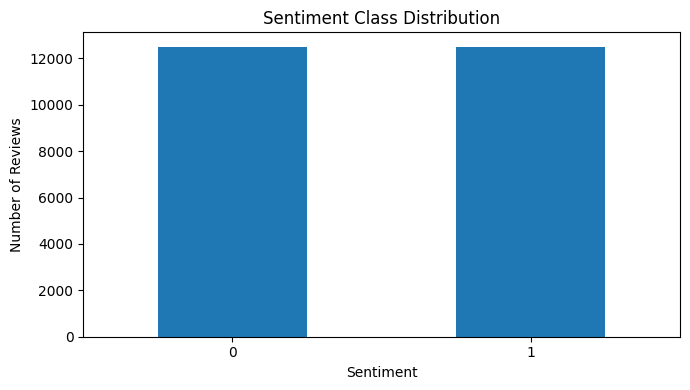


=== Review Length Statistics ===
             count       mean         std   min    25%    50%    75%     max
sentiment                                                                   
0          12500.0  229.83160  165.189994   4.0  128.0  174.0  281.0  1522.0
1          12500.0  231.51552  175.297727  10.0  125.0  172.0  282.0  2470.0


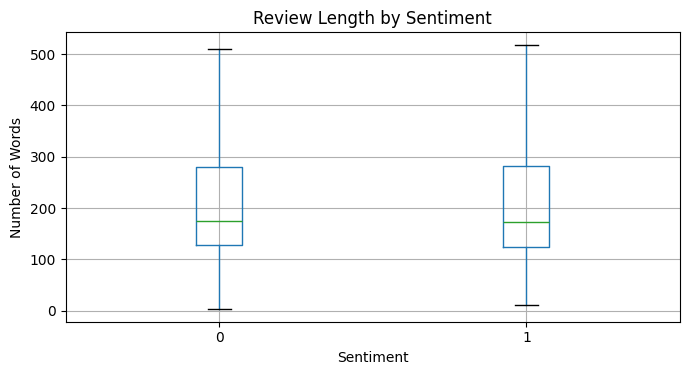

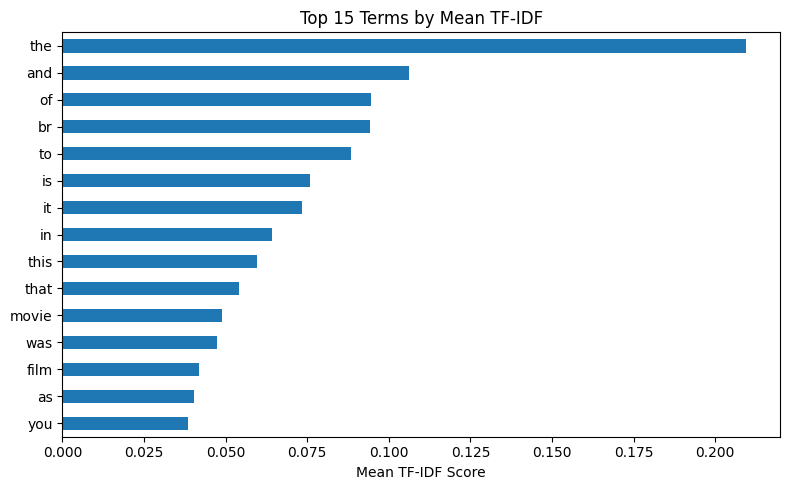


Plots saved to: C:\Users\pvwol\Skrivebord\Autumn_2026\BIG DATA RETAKE\laya_final\Big_data_exam\results\plots


In [3]:
from src.eda import run_eda

eda_results = run_eda(
    df=df_train, 
    text_col="review", 
    label_col="sentiment", 
    max_features=5000
)

In [4]:
traditional_file = Path("results/traditional_results.csv")
summary_file = Path("results/traditional_summary.csv")

if RUN_TRADITIONAL or not traditional_file.exists() or not summary_file.exists():
    results_df, summary_df = run_traditional_experiment(
        df_train, df_test, SIZES, SEEDS
    )
else:
    results_df = pd.read_csv(traditional_file)
    summary_df = pd.read_csv(summary_file)

print(
    summary_df
    .pivot(index="sample_size", columns="model", values="mean")
    .round(4)
)

model        Logistic Regression  Naive Bayes
sample_size                                  
100                       0.7205       0.7309
250                       0.7799       0.7805
500                       0.8030       0.8048
1000                      0.8376       0.8312
5000                      0.8783       0.8634
25000                     0.9028       0.8768


In [5]:
from src.traditional import fit_and_save_best_model

best_model, best_predictions = fit_and_save_best_model(
    df_train, df_test, results_df
)

# Get predictions and probabilities
lr_preds= best_predictions["traditional_prediction"].to_numpy()
lr_probs = best_predictions["traditional_probability"].to_numpy()


Selected model: Logistic Regression (training size=25000, seed=42)
CV accuracy: 0.8968
CV error rate: 0.1032
Best parameters: {'model__C': 10.0, 'tfidf__max_features': 20000, 'tfidf__min_df': 5, 'tfidf__ngram_range': (1, 2), 'tfidf__stop_words': None}
Test accuracy: 0.9022
Saved results\traditional_predictions.csv
Saved results\lr_predictions.csv


In [6]:
lr_file = "results/lr_predictions.csv"
pd.DataFrame({
    "review": df_test["review"],
    "sentiment": y_true,
    "lr_prediction": lr_preds,
    "lr_probability": lr_probs
}).to_csv(lr_file, index=False)

In [7]:
laya_file = "results/laya_predictions.csv"
laya_metrics_file = "results/laya_metrics.json"
laya_preds = None
laya_metrics = None

if RUN_LAYA:
    laya_metrics, laya_preds = laya_model.run_laya_batch_inference(
        df_test, batch_size=BATCH_SIZE
        )

    pd.DataFrame({
        "review": df_test["review"],
        "sentiment": y_true,
        "laya_prediction": laya_preds
    }).to_csv(laya_file, index=False)

    with open(laya_metrics_file, "w") as f:
        json.dump(laya_metrics, f, indent=2, default=float)

else:
    saved = pd.read_csv(laya_file)
    if (len(saved) != len(df_test)
            or not saved["review"].equals(df_test["review"])
            or not np.array_equal(saved["sentiment"].to_numpy(), y_true)):
        raise ValueError("Saved Laya predictions do not match this test set")

    laya_preds = saved["laya_prediction"].to_numpy(dtype=int)
    with open(laya_metrics_file) as f:
        laya_metrics = json.load(f)


if laya_preds is not None:
    laya_preds = np.asarray(laya_preds, dtype=int)
    print(f"Laya accuracy: {accuracy_score(y_true, laya_preds):.4f}")
    print(f"Laya F1: {laya_metrics['f1']:.4f}")

Laya accuracy: 0.9204
Laya F1: 0.9205


In [8]:
if laya_preds is not None:
    final_predictions = pd.DataFrame({
        "review": df_test["review"],
        "sentiment": y_true,
        "lr_prediction": lr_preds,
        "lr_probability": lr_probs,
        "laya_prediction": laya_preds
    })
    final_predictions.to_csv("results/final_predictions.csv", index=False)
    print("Saved results/final_predictions.csv")
else:
    print("Skipping: Laya predictions are not available")

Saved results/final_predictions.csv


In [9]:
if laya_preds is not None:
    stats_results = compare_models(y_true, lr_preds, laya_preds)
    print(pd.Series(stats_results).round(4))
    pd.Series(stats_results).to_json("results/statistical_comparison.json", indent=2)
else:
    print("Skipping: Laya predictions are not available")

Model 1 Accuracy            0.9022
Model 2 Accuracy            0.9204
Model 1 - Model 2          -0.0182
ci_lower                   -0.0224
ci_upper                   -0.0140
Model 1 Only correct:    1302.0000
Model 2 Only correct:    1758.0000
mcnemar_pvalue              0.0000
dtype: float64


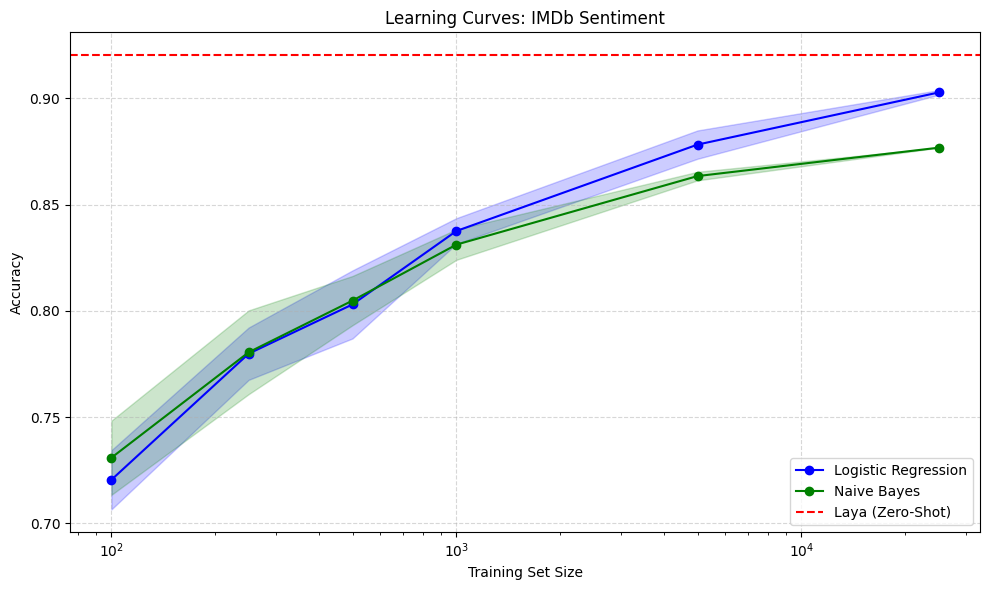

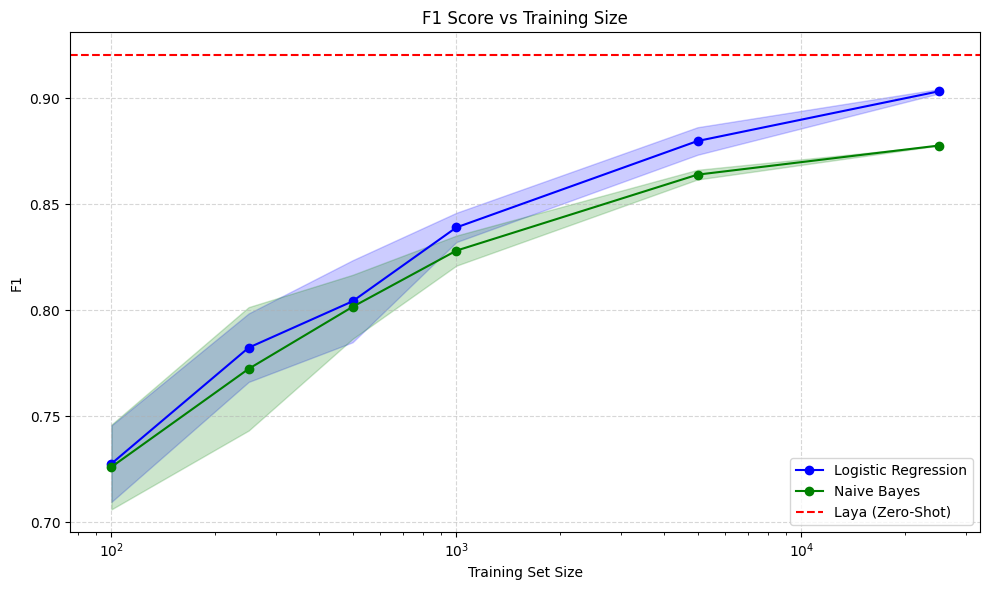

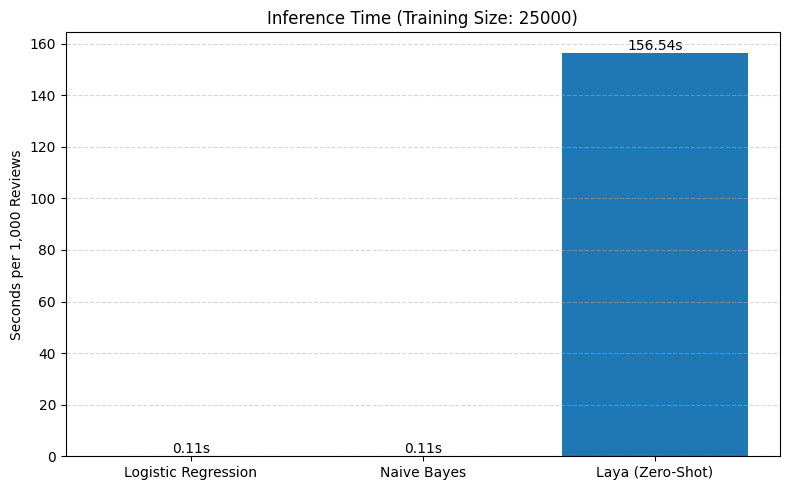

In [10]:
if laya_metrics is not None:
    plot_learning_curve(results_df, laya_metrics["accuracy"])
    plot_learning_curve(results_df, laya_metrics["f1"], metric="f1",
                        title="F1 Score vs Training Size")
    plot_efficiency(results_df, laya_metrics["infer_time_per_1k_sec"])
else:
    print("Skipping plots with Laya baseline")

In [11]:
# Extract true labels for train
y_train_true = df_train["sentiment"].to_numpy()

# 1. Get Traditional LR predictions and probabilities on train
lr_train_preds = best_model.predict(df_train["review"])
lr_train_probs = best_model.predict_proba(df_train["review"])[:, 1] 

# 2. Get Laya predictions on train 
laya_train_file = "results/laya_train_predictions.csv"
laya_train_preds = None

if RUN_LAYA:
    print("Running Laya inference on train set...")
    _, laya_train_preds = laya_model.run_laya_batch_inference(
        df_train, batch_size=BATCH_SIZE
    )
    
    # Save predictions to file
    pd.DataFrame({
        "review": df_train["review"],
        "sentiment": y_train_true,
        "laya_prediction": laya_train_preds
    }).to_csv(laya_train_file, index=False)
    print(f"Saved Laya train predictions to {laya_train_file}")

else:
    print(f"Loading Laya train predictions from {laya_train_file}...")
    saved_train = pd.read_csv(laya_train_file)
    
    # Sanity check to ensure the loaded data matches your current training set
    if len(saved_train) != len(df_train) or not np.array_equal(saved_train["sentiment"].to_numpy(), y_train_true):
        raise ValueError("Saved Laya train predictions do not match this training set")
        
    laya_train_preds = saved_train["laya_prediction"].to_numpy(dtype=int)

laya_train_preds = np.asarray(laya_train_preds, dtype=int)

Loading Laya train predictions from results/laya_train_predictions.csv...


In [12]:


# --------------------------------------------------
# 1. Prepare data and verify saved LAYA predictions
# --------------------------------------------------

X_train = df_train["review"].fillna("").astype(str).to_numpy()
y_train = df_train["sentiment"].to_numpy()

X_test = df_test["review"].fillna("").astype(str).to_numpy()
y_true = df_test["sentiment"].to_numpy()

saved_laya = pd.read_csv("results/laya_train_predictions.csv")

if (
    not np.array_equal(saved_laya["review"].to_numpy(), X_train)
    or not np.array_equal(saved_laya["sentiment"].to_numpy(), y_train)
):
    raise ValueError("Saved LAYA training predictions do not match df_train.")

laya_train_preds = saved_laya["laya_prediction"].to_numpy(dtype=int)
laya_preds = np.asarray(laya_preds, dtype=int)

# Optional inference budget.
# None = maximize validation accuracy without a usage constraint.
# 0.30 = allow at most 30% of reviews to be routed to LAYA.
MAX_LAYA_SHARE = None

param_grid = {
    **TFIDF_GRID,
    **MODEL_CONFIGS["Logistic Regression"]["params"]
}


# --------------------------------------------------
# 2. Outer CV: Generate out-of-fold LR predictions
# --------------------------------------------------

outer_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

oof_probs = np.empty(len(X_train))
oof_lr_preds = np.empty(len(X_train), dtype=int)

for fold, (train_idx, val_idx) in enumerate(
    outer_cv.split(X_train, y_train), start=1
):
    print(f"\n=== Outer fold {fold}/3 ===")

    inner_cv = StratifiedKFold(
        n_splits=3,
        shuffle=True,
        random_state=42
    )

    search = GridSearchCV(
        estimator=_pipeline("Logistic Regression"),
        param_grid=param_grid,
        scoring="accuracy",
        cv=inner_cv,
        n_jobs=-1,
        refit=True
    )

    # Hyperparameter tuning only uses outer training fold
    search.fit(X_train[train_idx], y_train[train_idx])

    # Predict on observations excluded from model fitting
    model = search.best_estimator_

    positive_idx = list(model.classes_).index(1)

    oof_probs[val_idx] = model.predict_proba(
        X_train[val_idx]
    )[:, positive_idx]

    oof_lr_preds[val_idx] = model.predict(
        X_train[val_idx]
    )

    print("Best parameters:", search.best_params_)
    print(
        "Outer fold accuracy:",
        accuracy_score(y_train[val_idx], oof_lr_preds[val_idx])
    )


# --------------------------------------------------
# 3. Optimize cascade thresholds using OOF predictions
# --------------------------------------------------

threshold_results = []

lowers = np.arange(5, 50, 5) / 100
uppers = np.arange(55, 100, 5) / 100

for lower in lowers:
    for upper in uppers:

        use_laya_oof = (
            (oof_probs > lower) &
            (oof_probs < upper)
        )

        preds = np.where(
            use_laya_oof,
            laya_train_preds,
            oof_lr_preds
        )

        threshold_results.append({
            "lower": round(lower, 2),
            "upper": round(upper, 2),
            "accuracy": accuracy_score(y_train, preds),
            "laya_share": use_laya_oof.mean()
        })

threshold_results = pd.DataFrame(threshold_results)

# Apply optional LAYA usage constraint
candidates = threshold_results.copy()

if MAX_LAYA_SHARE is not None:
    candidates = candidates[
        candidates["laya_share"] <= MAX_LAYA_SHARE
    ]

if candidates.empty:
    raise ValueError("No thresholds satisfy the LAYA usage constraint.")

# Maximize accuracy, breaking ties by minimizing LAYA usage
best = candidates.sort_values(
    ["accuracy", "laya_share"],
    ascending=[False, True]
).iloc[0]

best_lower = float(best["lower"])
best_upper = float(best["upper"])

print("\n=== THRESHOLD SELECTION ===")
print(f"Optimal thresholds: {best_lower:.2f}, {best_upper:.2f}")
print(f"OOF cascade accuracy: {best['accuracy']:.4f}")
print(f"OOF LAYA usage: {best['laya_share']:.1%}")

print("\nTop 10 configurations:")
print(
    candidates.sort_values(
        ["accuracy", "laya_share"],
        ascending=[False, True]
    ).head(10).to_string(index=False)
)


# --------------------------------------------------
# 4. Retune and fit LR using ALL training observations
# --------------------------------------------------

final_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

final_search = GridSearchCV(
    estimator=_pipeline("Logistic Regression"),
    param_grid=param_grid,
    scoring="accuracy",
    cv=final_cv,
    n_jobs=-1,
    refit=True
)

final_search.fit(X_train, y_train)

best_model = final_search.best_estimator_

print("\nFinal LR parameters:", final_search.best_params_)


# --------------------------------------------------
# 5. Evaluate on the held-out test set
# --------------------------------------------------

positive_idx = list(best_model.classes_).index(1)

lr_probs = best_model.predict_proba(X_test)[:, positive_idx]
lr_preds = best_model.predict(X_test)

# Thresholds are fixed from the OOF selection
use_laya = (
    (lr_probs > best_lower) &
    (lr_probs < best_upper)
)

cascade_preds = np.where(
    use_laya,
    laya_preds,
    lr_preds
)

cascade_acc = accuracy_score(y_true, cascade_preds)

print("\n=== FINAL TEST RESULTS ===")
print(f"Selected thresholds: {best_lower:.2f}, {best_upper:.2f}")
print(f"LR accuracy:      {accuracy_score(y_true, lr_preds):.4f}")
print(f"LAYA accuracy:    {accuracy_score(y_true, laya_preds):.4f}")
print(f"Cascade accuracy: {cascade_acc:.4f}")
print(f"LAYA usage:       {use_laya.mean():.1%}")
print(f"Fallback reviews: {use_laya.sum():,} / {len(use_laya):,}")

# Save threshold search results
Path("results").mkdir(exist_ok=True)
threshold_results.to_csv(
    "results/cascade_threshold_search.csv", index=False
)



=== Outer fold 1/3 ===
Best parameters: {'model__C': 10.0, 'tfidf__max_features': 20000, 'tfidf__min_df': 5, 'tfidf__ngram_range': (1, 2), 'tfidf__stop_words': None}
Outer fold accuracy: 0.9012479001679866

=== Outer fold 2/3 ===
Best parameters: {'model__C': 10.0, 'tfidf__max_features': 20000, 'tfidf__min_df': 5, 'tfidf__ngram_range': (1, 2), 'tfidf__stop_words': None}
Outer fold accuracy: 0.8975159006360255

=== Outer fold 3/3 ===
Best parameters: {'model__C': 10.0, 'tfidf__max_features': 20000, 'tfidf__min_df': 5, 'tfidf__ngram_range': (1, 2), 'tfidf__stop_words': None}
Outer fold accuracy: 0.8999159966398655

=== THRESHOLD SELECTION ===
Optimal thresholds: 0.15, 0.80
OOF cascade accuracy: 0.9328
OOF LAYA usage: 26.5%

Top 10 configurations:
 lower  upper  accuracy  laya_share
  0.15   0.80   0.93284     0.26548
  0.15   0.85   0.93284     0.29756
  0.10   0.80   0.93264     0.30684
  0.10   0.85   0.93264     0.33892
  0.15   0.90   0.93248     0.34244
  0.20   0.80   0.93232     

In [19]:
import time 
# Measure LR probability inference
start = time.perf_counter()
_ = best_model.predict_proba(df_test["review"])
lr_time = time.perf_counter() - start

# Reuse existing Laya timing
laya_time = laya_metrics["total_inference_time_sec"]

# Estimate cascade inference time
fallback_fraction = use_laya.mean()
estimated_cascade_time = lr_time + fallback_fraction * laya_time

print(f"Full Laya time: {laya_time:.2f} s")
print(f"LR time: {lr_time:.2f} s")
print(f"Estimated cascade time: {estimated_cascade_time:.2f} s")
print(f"Estimated speedup vs Laya: {laya_time / estimated_cascade_time:.2f}x")
print(f"Cascade seconds per 1k: {estimated_cascade_time / len(df_test) * 1000:.2f}")


Full Laya time: 3913.54 s
LR time: 11.61 s
Estimated cascade time: 932.23 s
Estimated speedup vs Laya: 4.20x
Cascade seconds per 1k: 37.29
